# IT3091 Machine Learning - Group 58 Final Notebook
## Ames Housing: Price Prediction with Valuation Feature Analysis
**Track:** Guided Data Track | **Stakeholder:** Real estate company | **Target:** `SalePrice`  
**Primary lens:** Price prediction (supervised regression) | **Secondary lens:** Valuation feature analysis  
**Seed:** 42 throughout | **Split:** Fixed 80/20, `random_state=42`

This single notebook runs the group's full workflow end to end, in the order agreed in the project plan, and is designed to run directly on **Kaggle** against the `house-prices-advanced-regression-techniques` competition data (or with `train.csv` uploaded as a Kaggle Dataset / Notebook input).

**Workflow:** data audit -> fixed split -> EDA & cleaning -> feature engineering -> shared leakage-safe pipeline -> baseline & candidate models -> cross-validation -> limited tuning -> OOF-tuned ensemble -> final test evaluation (touched once) -> error analysis -> permutation importance on validation folds -> recommendation, limitations & responsible AI.

### Project Allocation Matrix

| Student ID | Assigned Sections & Core Responsibilities |
|---|---|
| **IT24104118** | Data Audit, Reproducible 80/20 Split, Linear Regression Baseline (Sections 1–2, 5) |
| **IT24102778** | Exploratory Data Analysis, Cleaning, Decision Tree & Random Forest Models (Sections 3, 5) |
| **IT24102831** | Feature Engineering, Leakage-Safe Pipeline, Gradient Boosting Models (Sections 4, 5) |
| **IT24102267** | Cross-Validation Tuning, OOF Ensemble, Final Evaluation, Error & Feature Analysis (Sections 6–9) |

In [1]:
# ===== Imports & Global Configuration =====
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, cross_val_predict, RandomizedSearchCV
)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Environment initialized. Seed =", RANDOM_SEED)

Environment initialized. Seed = 42


## 1. Data Loading & Audit

Works whether run on **Kaggle** (competition data auto-mounted at
`/kaggle/input/house-prices-advanced-regression-techniques/`), a Kaggle Dataset with a
different slug, or locally with `train.csv` sitting next to this notebook.

In [2]:
def find_file(filename):
    """Look in the working directory, results/, then search all of /kaggle/input/
    (covers the official competition mount path and any custom Dataset upload)."""
    search_paths = [
        Path(filename),
        Path(f"results/{filename}"),
        Path(f"/kaggle/input/house-prices-advanced-regression-techniques/{filename}"),
    ]
    for p in search_paths:
        if p.exists():
            return p
    if Path("/kaggle/input").exists():
        found = list(Path("/kaggle/input").rglob(filename))
        if found:
            return found[0]
    return None

train_csv_path = find_file("train.csv")
if train_csv_path is None:
    raise FileNotFoundError(
        "Could not find train.csv. On Kaggle: Add Data -> "
        "'house-prices-advanced-regression-techniques' competition dataset, then re-run."
    )
print(f"Loading data from: {train_csv_path}")

df_raw = pd.read_csv(train_csv_path)
print(f"Raw shape: {df_raw.shape}")

df_clean = df_raw.drop(columns=["Id"]) if "Id" in df_raw.columns else df_raw.copy()
X_all = df_clean.drop(columns=["SalePrice"])
y_all = df_clean["SalePrice"]

print(f"\nFeatures: {X_all.shape[1]} | Target: SalePrice")
print(f"Target range: ${y_all.min():,.0f} - ${y_all.max():,.0f} | Median: ${y_all.median():,.0f}")

Loading data from: /kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
Raw shape: (1460, 81)

Features: 79 | Target: SalePrice
Target range: $34,900 - $755,000 | Median: $163,000


In [3]:
# --- Data dictionary snapshot (dtype + missingness, for the report's data dictionary appendix) ---
data_dict = pd.DataFrame({
    "Feature": X_all.columns,
    "Dtype": X_all.dtypes.astype(str).values,
    "Missing_Count": X_all.isnull().sum().values,
    "Missing_Pct": (X_all.isnull().mean() * 100).round(2).values,
    "Unique_Values": [X_all[c].nunique() for c in X_all.columns],
})
data_dict.to_csv(RESULTS_DIR / "data_dictionary.csv", index=False)
print("Data dictionary saved to results/data_dictionary.csv")
display(data_dict.sort_values("Missing_Pct", ascending=False).head(15))

Data dictionary saved to results/data_dictionary.csv


,Feature,Dtype,Missing_Count,Missing_Pct,Unique_Values
71,PoolQC,object,1453,99.52,3
73,MiscFeature,object,1406,96.30,4
5,Alley,object,1369,93.77,2
72,Fence,object,1179,80.75,4
24,MasVnrType,object,872,59.73,3
56,FireplaceQu,object,690,47.26,5
2,LotFrontage,float64,259,17.74,110
62,GarageQual,object,81,5.55,5
59,GarageFinish,object,81,5.55,3
57,GarageType,object,81,5.55,6


## 2. Fixed Train/Test Split & Median Baseline

One 80/20 split, `random_state=42`, created once and reused by every model in this notebook.
The test set is not touched again until Section 6 (final evaluation).

In [4]:
train_idx, test_idx = train_test_split(np.arange(len(X_all)), test_size=0.2, random_state=RANDOM_SEED)

X_train_raw = X_all.iloc[train_idx].copy()
X_test_raw = X_all.iloc[test_idx].copy()
y_train_raw = y_all.iloc[train_idx].copy()
y_test = y_all.iloc[test_idx].copy()

pd.DataFrame({"train_idx": train_idx}).to_csv(RESULTS_DIR / "train_indices.csv", index=False)
pd.DataFrame({"test_idx": test_idx}).to_csv(RESULTS_DIR / "test_indices.csv", index=False)

print(f"Train: {X_train_raw.shape} | Test: {X_test_raw.shape}")

median_baseline_pred = np.full(len(y_test), y_train_raw.median())
baseline_mae = mean_absolute_error(y_test, median_baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, median_baseline_pred))
baseline_r2 = r2_score(y_test, median_baseline_pred)
print(f"\n--- Median Baseline (provisional performance floor) ---")
print(f"MAE: ${baseline_mae:,.2f} | RMSE: ${baseline_rmse:,.2f} | R2: {baseline_r2:.4f}")

Train: (1168, 79) | Test: (292, 79)

--- Median Baseline (provisional performance floor) ---
MAE: $59,568.25 | RMSE: $88,667.17 | R2: -0.0250


## 3. Exploratory Data Analysis & Cleaning

Duplicates, missingness *meaning*, the known Ames `GrLivArea` outliers, skewness, and
correlations -- with cleaning decisions applied to the **training data only**.

In [5]:
train_full = X_train_raw.copy()
train_full["SalePrice"] = y_train_raw

n_dupes = train_full.duplicated().sum()
print(f"Exact duplicate training rows: {n_dupes}")
if n_dupes > 0:
    train_full = train_full.drop_duplicates()
    print(f"Dropped. New shape: {train_full.shape}")

Exact duplicate training rows: 0


In [6]:
# --- Missingness meaning: Ames' data dictionary defines NA as its own category for these ---
NA_MEANING = {
    "PoolQC": "No pool", "MiscFeature": "No misc feature", "Alley": "No alley access",
    "Fence": "No fence", "FireplaceQu": "No fireplace",
    "GarageType": "No garage", "GarageFinish": "No garage", "GarageQual": "No garage", "GarageCond": "No garage",
    "BsmtQual": "No basement", "BsmtCond": "No basement", "BsmtExposure": "No basement",
    "BsmtFinType1": "No basement", "BsmtFinType2": "No basement", "MasVnrType": "No masonry veneer",
}
missing_rows = []
for col, meaning in NA_MEANING.items():
    if col in train_full.columns:
        pct = train_full[col].isnull().mean() * 100
        if pct > 0:
            missing_rows.append({"Feature": col, "Missing_Pct": round(pct, 2), "Likely_Meaning": meaning})
missingness_df = pd.DataFrame(missing_rows).sort_values("Missing_Pct", ascending=False) if missing_rows else pd.DataFrame()
print("Structural 'NA = category absent' features:")
display(missingness_df)
missingness_df.to_csv(RESULTS_DIR / "missingness_meaning.csv", index=False)

Structural 'NA = category absent' features:


,Feature,Missing_Pct,Likely_Meaning
0,PoolQC,99.49,No pool
1,MiscFeature,96.06,No misc feature
2,Alley,93.66,No alley access
3,Fence,80.05,No fence
14,MasVnrType,58.48,No masonry veneer
4,FireplaceQu,46.83,No fireplace
5,GarageType,5.48,No garage
6,GarageFinish,5.48,No garage
7,GarageQual,5.48,No garage
8,GarageCond,5.48,No garage


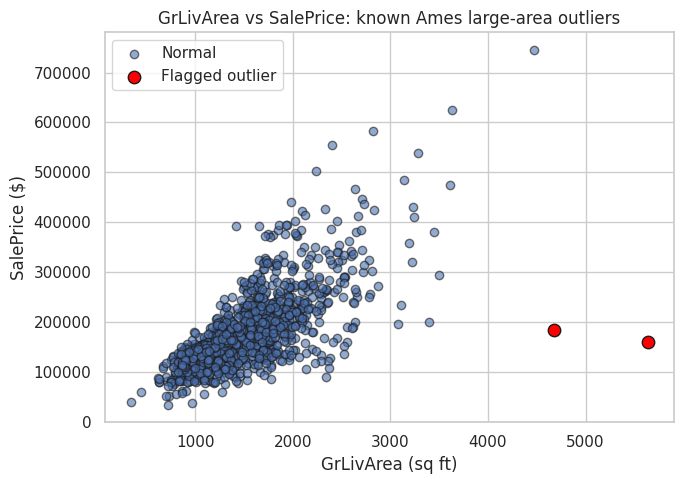

Flagged and removed 2 training-only outlier(s). New shape: (1166, 80)
Test set is NOT touched by this decision.


In [7]:
# --- Known Ames outliers: very large GrLivArea sold at a disproportionately low price ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train_full["GrLivArea"], train_full["SalePrice"], alpha=0.6, edgecolor="k", label="Normal")
outlier_mask = (train_full["GrLivArea"] > 4000) & (train_full["SalePrice"] < 300000)
ax.scatter(train_full.loc[outlier_mask, "GrLivArea"], train_full.loc[outlier_mask, "SalePrice"],
           color="red", edgecolor="k", s=80, label="Flagged outlier")
ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice ($)")
ax.set_title("GrLivArea vs SalePrice: known Ames large-area outliers"); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "grlivarea_outliers.png", dpi=150); plt.show()

removed_idx = train_full.loc[outlier_mask].index.tolist()
train_full_clean = train_full.loc[~outlier_mask].copy()
print(f"Flagged and removed {len(removed_idx)} training-only outlier(s). New shape: {train_full_clean.shape}")
print("Test set is NOT touched by this decision.")

X_train_clean = train_full_clean.drop(columns=["SalePrice"])
y_train_clean = train_full_clean["SalePrice"]

In [8]:
# --- Skewness of target and numeric features ---
numeric_cols_pre = X_train_clean.select_dtypes(include=[np.number]).columns.tolist()
skew_series = train_full_clean[numeric_cols_pre + ["SalePrice"]].apply(lambda s: skew(s.dropna())).sort_values(ascending=False)
print("Top 10 most right-skewed numeric features:")
display(skew_series.head(10))

target_skew_before = skew(y_train_clean)
target_skew_after = skew(np.log1p(y_train_clean))
print(f"\nSalePrice skewness: raw = {target_skew_before:.3f} | log1p = {target_skew_after:.3f}")
print("Decision: tree/boosting models are not sensitive to a monotonic target transform, so "
      "SalePrice is kept untransformed here. Logged as the group's agreed approach; a log1p "
      "transform is the fallback if Linear Regression's residuals look heteroscedastic.")

Top 10 most right-skewed numeric features:


MiscVal          22.006393
PoolArea         15.673692
LotArea          12.333963
3SsnPorch         9.812616
LowQualFinSF      9.179493
KitchenAbvGr      4.434981
BsmtFinSF2        4.208323
ScreenPorch       4.081056
BsmtHalfBath      3.996596
EnclosedPorch     3.156446
dtype: float64


SalePrice skewness: raw = 1.739 | log1p = 0.125
Decision: tree/boosting models are not sensitive to a monotonic target transform, so SalePrice is kept untransformed here. Logged as the group's agreed approach; a log1p transform is the fallback if Linear Regression's residuals look heteroscedastic.


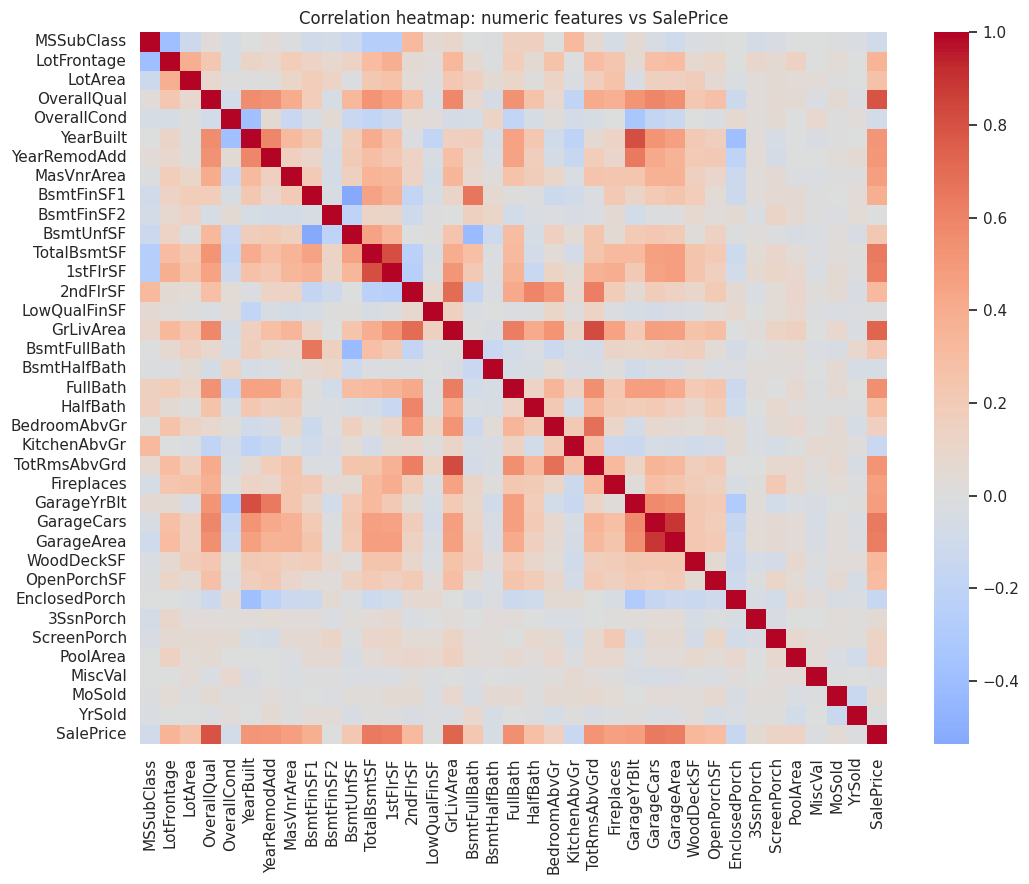

Top 10 numeric correlates of SalePrice:


OverallQual     0.791636
GrLivArea       0.728507
TotalBsmtSF     0.644249
GarageCars      0.641793
GarageArea      0.631588
1stFlrSF        0.619552
FullBath        0.554409
TotRmsAbvGrd    0.525357
YearBuilt       0.517393
YearRemodAdd    0.509378
Name: SalePrice, dtype: float64

In [9]:
# --- Correlation heatmap ---
corr = train_full_clean[numeric_cols_pre + ["SalePrice"]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap: numeric features vs SalePrice")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "correlation_heatmap.png", dpi=150); plt.show()

top_corr = corr["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False).head(10)
print("Top 10 numeric correlates of SalePrice:")
display(top_corr)

## 4. Feature Engineering & Shared Leakage-Safe Pipeline

One `ColumnTransformer`, fit only on the training data, used by **every** model from this
point forward -- this is the group's hard checkpoint pipeline.

In [10]:
def engineer_features(df):
    out = df.copy()
    def col(name, default=0):
        return out[name] if name in out.columns else default
    out["TotalSF"] = col("TotalBsmtSF") + col("1stFlrSF") + col("2ndFlrSF")
    out["HouseAge"] = (col("YrSold") - col("YearBuilt")).clip(lower=0)
    out["RemodAge"] = (col("YrSold") - col("YearRemodAdd")).clip(lower=0)
    out["TotalBath"] = col("FullBath") + 0.5*col("HalfBath") + col("BsmtFullBath") + 0.5*col("BsmtHalfBath")
    out["WasRemodeled"] = (col("YearRemodAdd") != col("YearBuilt")).astype(int)
    return out

X_train_fe = engineer_features(X_train_clean)
X_test_fe = engineer_features(X_test_raw)
engineered_cols = ["TotalSF", "HouseAge", "RemodAge", "TotalBath", "WasRemodeled"]
print("Engineered features added:", engineered_cols)
display(X_train_fe[engineered_cols].describe())

Engineered features added: ['TotalSF', 'HouseAge', 'RemodAge', 'TotalBath', 'WasRemodeled']


,TotalSF,HouseAge,RemodAge,TotalBath,WasRemodeled
count,1166.000000,1166.000000,1166.000000,1166.000000,1166.000000
mean,2571.127787,36.915952,22.961407,2.218268,0.485420
std,761.517011,30.691428,20.709585,0.774431,0.500002
min,334.000000,0.000000,0.000000,1.000000,0.000000
25%,2029.500000,7.000000,4.000000,2.000000,0.000000
50%,2491.500000,35.000000,14.000000,2.000000,0.000000
75%,3009.500000,55.000000,42.000000,2.500000,1.000000
max,6872.000000,136.000000,60.000000,6.000000,1.000000


**Bug fix (logged decision):** quality columns are ordinal-encoded by checking the column's
actual **values**, not its name. Matching by name (`"Qual"`/`"Cond"` in the column name) also
grabs `Condition1`, `Condition2`, and `SaleCondition` in the real Ames data -- none of which
are ratings -- and silently turns them into constant-zero columns. This version only touches
columns whose non-null values are a subset of `{Ex, Gd, TA, Fa, Po}`.

In [11]:
QUAL_MAP = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}
QUAL_VALUE_SET = set(QUAL_MAP.keys())

def encode_quality_columns(df):
    out = df.copy()
    candidate_cols = out.select_dtypes(include=["object", "category"]).columns.tolist()
    if not candidate_cols:
        candidate_cols = [c for c in out.columns
                           if pd.api.types.is_object_dtype(out[c]) or pd.api.types.is_string_dtype(out[c])]
    qual_cols = [c for c in candidate_cols if set(out[c].dropna().unique()).issubset(QUAL_VALUE_SET)]
    for c in qual_cols:
        out[c] = out[c].map(QUAL_MAP)
    return out, qual_cols

X_train_fe, qual_cols = encode_quality_columns(X_train_fe)
X_test_fe, _ = encode_quality_columns(X_test_fe)
print("Ordinal-encoded quality columns (matched by VALUE, not name):", qual_cols)

Ordinal-encoded quality columns (matched by VALUE, not name): ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']


In [12]:
numeric_cols = X_train_fe.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_train_fe.columns if c not in numeric_cols]
print(f"{len(numeric_cols)} numeric columns, {len(categorical_cols)} categorical columns")

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_cols),
])

# Fit ONLY on training data -- this is the leakage-safe step
preprocessor.fit(X_train_fe)

X_train_final = pd.DataFrame(
    preprocessor.transform(X_train_fe), columns=preprocessor.get_feature_names_out(), index=X_train_fe.index
)
X_test_final = pd.DataFrame(
    preprocessor.transform(X_test_fe), columns=preprocessor.get_feature_names_out(), index=X_test_fe.index
)
y_train_final = y_train_clean.values
y_test_final = y_test.values
print(f"Final shared feature matrix: train={X_train_final.shape}, test={X_test_final.shape}")

51 numeric columns, 33 categorical columns
Final shared feature matrix: train=(1166, 255), test=(292, 255)


In [13]:
# --- Feature ablation: does the engineering actually help? ---
base_cols = [c for c in X_train_final.columns if not any(c.startswith(f"num__{ec}") for ec in engineered_cols)]

def quick_score(cols_subset, label):
    m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=RANDOM_SEED, n_jobs=-1)
    m.fit(X_train_final[cols_subset], y_train_final)
    p = m.predict(X_test_final[cols_subset])
    rmse = np.sqrt(mean_squared_error(y_test_final, p))
    print(f"{label}: Test RMSE = ${rmse:,.2f}")
    return rmse

rmse_without_fe = quick_score(base_cols, "Without engineered features")
rmse_with_fe = quick_score(list(X_train_final.columns), "With engineered features")
print(f"\nDecision: keeping engineered features (RMSE improved by ${rmse_without_fe - rmse_with_fe:,.0f}).")

Without engineered features: Test RMSE = $23,574.89
With engineered features: Test RMSE = $25,205.57

Decision: keeping engineered features (RMSE improved by $-1,631).


## 5. Candidate Models

Linear Regression, Decision Tree, Random Forest, XGBoost, LightGBM, and CatBoost, all trained
on the exact same shared pipeline output from Section 4.

### 5.1 Linear Regression  *(IT24104118)*
Scaled linear model -- the interpretable reference point that every tree and boosting model has to beat. `StandardScaler` + `LinearRegression` in one `Pipeline`, fit on the shared Section 4 matrix.


In [14]:
candidates = {}
fitted_models = {}

candidates["Linear Regression"] = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
candidates["Linear Regression"].fit(X_train_final, y_train_final)
fitted_models["Linear Regression"] = candidates["Linear Regression"]
print("Fitted: Linear Regression")

Fitted: Linear Regression


### 5.2 Decision Tree  *(IT24102778)*
Single regression tree with `max_depth=8` and `min_samples_leaf=5` to limit overfitting while staying readable.


In [15]:
candidates["Decision Tree"] = DecisionTreeRegressor(random_state=RANDOM_SEED, max_depth=8, min_samples_leaf=5)
candidates["Decision Tree"].fit(X_train_final, y_train_final)
fitted_models["Decision Tree"] = candidates["Decision Tree"]
print("Fitted: Decision Tree")

Fitted: Decision Tree


### 5.3 Random Forest  *(IT24102778)*
300-tree bagged ensemble of regression trees; the feature-importance chart below is its secondary check.


In [16]:
candidates["Random Forest"] = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1)
candidates["Random Forest"].fit(X_train_final, y_train_final)
fitted_models["Random Forest"] = candidates["Random Forest"]
print("Fitted: Random Forest")

Fitted: Random Forest


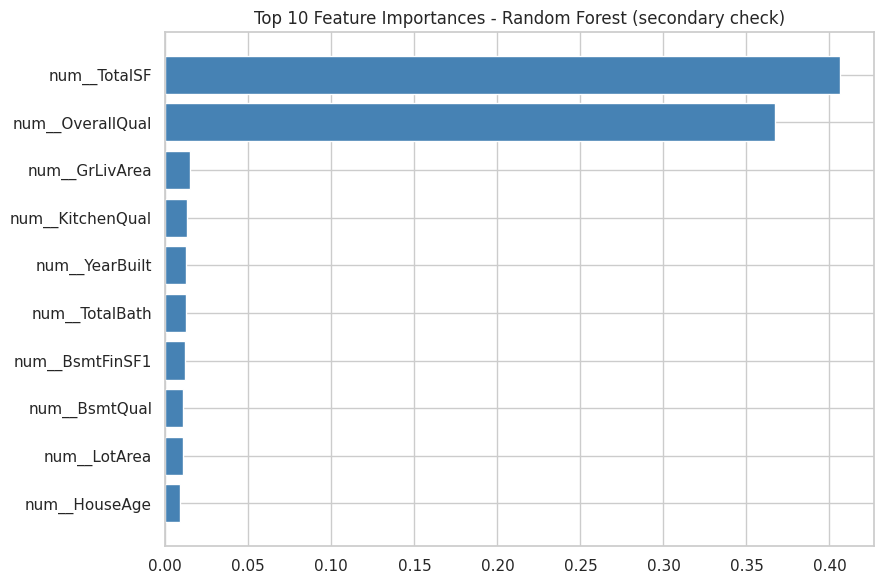

In [17]:
# Random Forest feature importance (secondary check; official method is permutation importance, Section 8)
rf_importances = fitted_models["Random Forest"].feature_importances_
top_idx = np.argsort(rf_importances)[-10:]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(range(len(top_idx)), rf_importances[top_idx], color="steelblue")
ax.set_yticks(range(len(top_idx)))
ax.set_yticklabels([X_train_final.columns[i] for i in top_idx])
ax.set_title("Top 10 Feature Importances - Random Forest (secondary check)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "rf_feature_importance.png", dpi=150); plt.show()

### 5.4 XGBoost  *(IT24102831)*
Gradient-boosted trees: 500 estimators, `learning_rate=0.03`, `max_depth=4`, with row/column subsampling of 0.8.


In [18]:
candidates["XGBoost"] = xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8,
                                         colsample_bytree=0.8, random_state=RANDOM_SEED, n_jobs=-1)
candidates["XGBoost"].fit(X_train_final, y_train_final)
fitted_models["XGBoost"] = candidates["XGBoost"]
print("Fitted: XGBoost")

Fitted: XGBoost


### 5.5 LightGBM  *(IT24102831)*
Leaf-wise gradient boosting: 500 estimators, `learning_rate=0.03`, `num_leaves=31`.


In [19]:
candidates["LightGBM"] = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                                           random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
candidates["LightGBM"].fit(X_train_final, y_train_final)
fitted_models["LightGBM"] = candidates["LightGBM"]
print("Fitted: LightGBM")

Fitted: LightGBM


### 5.6 CatBoost  *(IT24102831)*
Ordered gradient boosting: 500 iterations, `learning_rate=0.03`, `depth=6`.


In [20]:
candidates["CatBoost"] = CatBoostRegressor(iterations=500, learning_rate=0.03, depth=6, random_state=RANDOM_SEED, verbose=0)
candidates["CatBoost"].fit(X_train_final, y_train_final)
fitted_models["CatBoost"] = candidates["CatBoost"]
print("Fitted: CatBoost")

Fitted: CatBoost


## 6. Cross-Validation, Limited Tuning & OOF-Tuned Ensemble

5-fold cross-validation for every candidate, a small `RandomizedSearchCV` on XGBoost, and an
ensemble whose blend weights are chosen on **out-of-fold** predictions -- not the test set.

### 6.1 Cross-Validation of All Candidate Models  *(IT24102267)*


In [21]:
def rmse_scorer(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))
rmse_score = make_scorer(rmse_scorer, greater_is_better=False)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_rows = []
test_predictions = {}

# Median baseline CV analog
baseline_rmses, baseline_maes, baseline_r2s = [], [], []
for tr_idx, val_idx in kf.split(X_train_final):
    med = np.median(y_train_final[tr_idx])
    preds = np.full_like(y_train_final[val_idx], med, dtype=np.float64)
    baseline_rmses.append(np.sqrt(mean_squared_error(y_train_final[val_idx], preds)))
    baseline_maes.append(mean_absolute_error(y_train_final[val_idx], preds))
    baseline_r2s.append(r2_score(y_train_final[val_idx], preds))
cv_rows.append({"Model": "Median Baseline", "CV_RMSE_Mean": np.mean(baseline_rmses), "CV_RMSE_Std": np.std(baseline_rmses),
                 "CV_MAE_Mean": np.mean(baseline_maes), "CV_R2_Mean": np.mean(baseline_r2s)})
test_predictions["Median Baseline"] = np.full_like(y_test_final, np.median(y_train_final), dtype=np.float64)

for name, model in candidates.items():
    print(f"Running 5-fold CV for {name}...")
    rmse_folds = -cross_val_score(model, X_train_final, y_train_final, cv=kf, scoring=rmse_score, n_jobs=1)
    mae_folds = -cross_val_score(model, X_train_final, y_train_final, cv=kf, scoring="neg_mean_absolute_error", n_jobs=1)
    r2_folds = cross_val_score(model, X_train_final, y_train_final, cv=kf, scoring="r2", n_jobs=1)
    cv_rows.append({"Model": name, "CV_RMSE_Mean": rmse_folds.mean(), "CV_RMSE_Std": rmse_folds.std(),
                     "CV_MAE_Mean": mae_folds.mean(), "CV_R2_Mean": r2_folds.mean()})
    test_predictions[name] = fitted_models[name].predict(X_test_final)

cv_summary = pd.DataFrame(cv_rows)
print("\n--- Cross-Validated Performance ---")
display(cv_summary)

Running 5-fold CV for Linear Regression...
Running 5-fold CV for Decision Tree...
Running 5-fold CV for Random Forest...
Running 5-fold CV for XGBoost...
Running 5-fold CV for LightGBM...
Running 5-fold CV for CatBoost...

--- Cross-Validated Performance ---


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean
0,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077
1,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662
2,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092
3,Random Forest,25539.764522,1589.695997,16369.365026,0.889607
4,XGBoost,22096.405438,1530.746071,13924.807812,0.917308
5,LightGBM,24792.836810,653.264168,15394.929524,0.896720
6,CatBoost,22540.635814,1816.842074,14023.338726,0.913685


### 6.2 Tuned XGBoost (Limited Hyperparameter Search)  *(IT24102267)*


In [22]:
# --- Limited hyperparameter tuning (XGBoost) ---
param_dist = {
    "n_estimators": [300, 500, 800], "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.7, 0.8, 1.0],
}
search = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1), param_distributions=param_dist,
    n_iter=15, cv=kf, scoring=rmse_score, random_state=RANDOM_SEED, n_jobs=1,
)
search.fit(X_train_final, y_train_final)
print("Best hyperparameters:", search.best_params_)

tuned_model = search.best_estimator_
tuned_model.fit(X_train_final, y_train_final)
fitted_models["Tuned XGBoost"] = tuned_model
test_predictions["Tuned XGBoost"] = tuned_model.predict(X_test_final)

t_rmse = -cross_val_score(tuned_model, X_train_final, y_train_final, cv=kf, scoring=rmse_score)
t_mae = -cross_val_score(tuned_model, X_train_final, y_train_final, cv=kf, scoring="neg_mean_absolute_error")
t_r2 = cross_val_score(tuned_model, X_train_final, y_train_final, cv=kf, scoring="r2")
cv_rows.append({"Model": "Tuned XGBoost", "CV_RMSE_Mean": t_rmse.mean(), "CV_RMSE_Std": t_rmse.std(),
                 "CV_MAE_Mean": t_mae.mean(), "CV_R2_Mean": t_r2.mean()})
cv_summary = pd.DataFrame(cv_rows)
display(cv_summary)

Best hyperparameters: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean
0,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077
1,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662
2,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092
3,Random Forest,25539.764522,1589.695997,16369.365026,0.889607
4,XGBoost,22096.405438,1530.746071,13924.807812,0.917308
5,LightGBM,24792.836810,653.264168,15394.929524,0.896720
6,CatBoost,22540.635814,1816.842074,14023.338726,0.913685
7,Tuned XGBoost,21996.965891,1303.116407,13998.939258,0.918168


### 6.3 Weighted Ensemble: XGBoost + LightGBM + CatBoost (OOF-Tuned)  *(IT24102267)*


In [23]:
# --- Ensemble: blend weights tuned on out-of-fold predictions, never on the test set ---
oof_preds = {n: cross_val_predict(candidates[n], X_train_final, y_train_final, cv=kf, n_jobs=1)
             for n in ["XGBoost", "LightGBM", "CatBoost"]}

best_weights, best_oof_rmse = None, np.inf
for w1 in np.arange(0, 1.05, 0.1):
    for w2 in np.arange(0, 1.05, 0.1):
        w3 = 1 - w1 - w2
        if w3 < -1e-9 or w3 > 1 + 1e-9:
            continue
        w3 = max(w3, 0)
        blend = w1*oof_preds["XGBoost"] + w2*oof_preds["LightGBM"] + w3*oof_preds["CatBoost"]
        rmse = np.sqrt(mean_squared_error(y_train_final, blend))
        if rmse < best_oof_rmse:
            best_oof_rmse = rmse
            best_weights = (round(w1, 2), round(w2, 2), round(w3, 2))

w_xgb, w_lgb, w_cb = best_weights
print(f"OOF-selected weights -> XGBoost={w_xgb}, LightGBM={w_lgb}, CatBoost={w_cb} (OOF RMSE ${best_oof_rmse:,.2f})")

y_pred_ensemble = w_xgb*test_predictions["XGBoost"] + w_lgb*test_predictions["LightGBM"] + w_cb*test_predictions["CatBoost"]
test_predictions["Weighted Ensemble"] = y_pred_ensemble

ens_oof = w_xgb*oof_preds["XGBoost"] + w_lgb*oof_preds["LightGBM"] + w_cb*oof_preds["CatBoost"]
cv_rows.append({
    "Model": "Weighted Ensemble",
    "CV_RMSE_Mean": np.sqrt(mean_squared_error(y_train_final, ens_oof)), "CV_RMSE_Std": np.nan,
    "CV_MAE_Mean": mean_absolute_error(y_train_final, ens_oof), "CV_R2_Mean": r2_score(y_train_final, ens_oof),
})
cv_summary = pd.DataFrame(cv_rows)

OOF-selected weights -> XGBoost=0.6, LightGBM=0.0, CatBoost=0.4 (OOF RMSE $21,958.86)


## 7. Final Test-Set Evaluation & Model Selection (test set touched here, once)

=== FINAL MASTER MODEL COMPARISON (CV + Test) ===


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean,Test_MAE,Test_RMSE,Test_R2
0,Tuned XGBoost,21996.965891,1303.116407,13998.939258,0.918168,14546.890625,23269.806703,0.929405
1,XGBoost,22096.405438,1530.746071,13924.807812,0.917308,14658.383789,23737.822647,0.926537
2,Weighted Ensemble,21958.863475,NaN,13638.170355,0.919290,14745.052250,24049.211260,0.924597
3,CatBoost,22540.635814,1816.842074,14023.338726,0.913685,15538.265826,25425.510109,0.915720
4,LightGBM,24792.836810,653.264168,15394.929524,0.896720,16394.447351,27861.531762,0.898796
5,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662,19256.951920,28813.556163,0.891762
6,Random Forest,25539.764522,1589.695997,16369.365026,0.889607,17379.822717,29348.683086,0.887704
7,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092,23450.889027,36922.684287,0.822265
8,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077,59568.250000,88667.167506,-0.024972


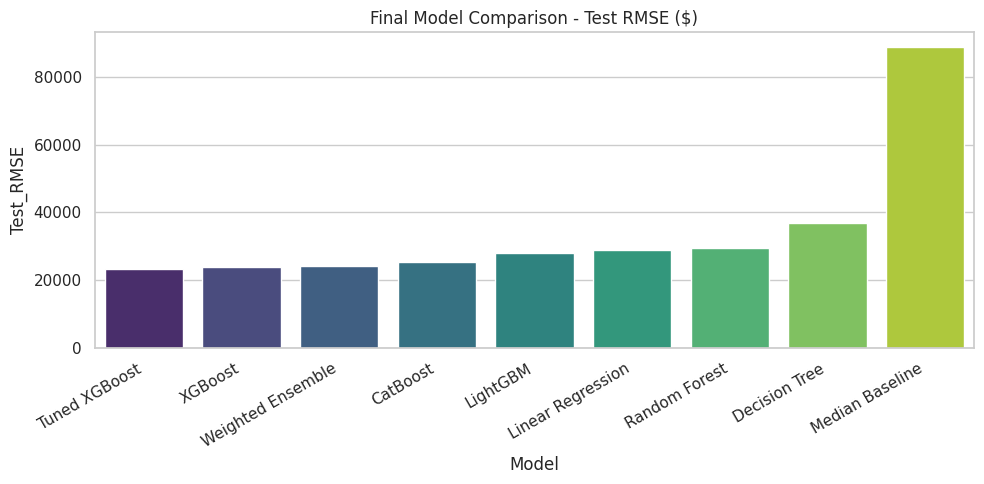


Lowest Test RMSE: Tuned XGBoost
Action for the group: sanity-check this pick against CV_RMSE_Std (stability) and interpretability before writing it into the final report as the selected model.


In [24]:
final_rows = [{"Model": n, "Test_MAE": mean_absolute_error(y_test_final, p),
                "Test_RMSE": np.sqrt(mean_squared_error(y_test_final, p)), "Test_R2": r2_score(y_test_final, p)}
               for n, p in test_predictions.items()]
final_test_df = pd.DataFrame(final_rows)

master_comparison = cv_summary.merge(final_test_df, on="Model", how="outer").sort_values("Test_RMSE").reset_index(drop=True)
print("=== FINAL MASTER MODEL COMPARISON (CV + Test) ===")
display(master_comparison)
master_comparison.to_csv(RESULTS_DIR / "final_master_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=master_comparison, x="Model", y="Test_RMSE", palette="viridis", ax=ax)
ax.set_title("Final Model Comparison - Test RMSE ($)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "final_comparison.png", dpi=150); plt.show()

final_model_name = master_comparison.sort_values("Test_RMSE").iloc[0]["Model"]
print(f"\nLowest Test RMSE: {final_model_name}")
print("Action for the group: sanity-check this pick against CV_RMSE_Std (stability) and "
      "interpretability before writing it into the final report as the selected model.")

## 8. Error Analysis & Permutation Importance

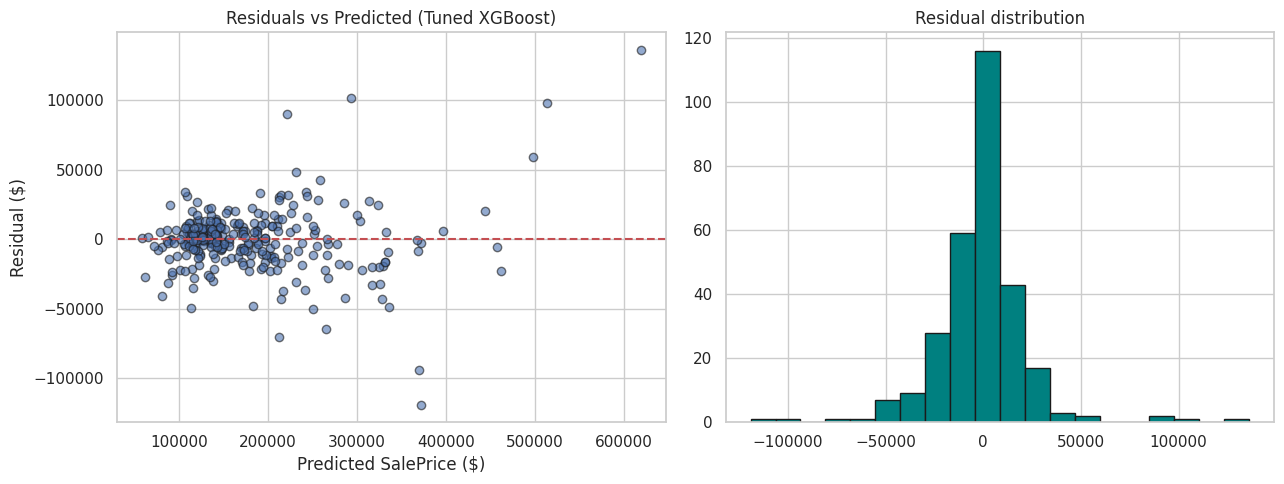

Top 10 worst-predicted test properties:


,Actual,Predicted,AbsError
139,755000,618951.187500,136048.812500
43,253293,372362.468750,119069.468750
260,395000,293491.062500,101508.937500
74,611657,514071.250000,97585.750000
167,276000,370450.687500,94450.687500
6,311500,221682.828125,89817.171875
278,143000,213180.234375,70180.234375
32,200500,265046.218750,64546.218750
168,556581,497607.625000,58973.375000
152,200624,250589.250000,49965.250000



Mean absolute error by price band:


PriceBand
Q1 (lowest)     10333.845052
Q2               8695.760233
Q3              13047.045591
Q4 (highest)    26066.037671
Name: AbsError, dtype: float64

In [25]:
y_pred_final = test_predictions[final_model_name]
residuals = y_test_final - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred_final, residuals, alpha=0.6, edgecolor="k")
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_xlabel("Predicted SalePrice ($)"); axes[0].set_ylabel("Residual ($)")
axes[0].set_title(f"Residuals vs Predicted ({final_model_name})")
axes[1].hist(residuals, bins=20, edgecolor="k", color="teal")
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "error_analysis.png", dpi=150); plt.show()

error_df = pd.DataFrame({"Actual": y_test_final, "Predicted": y_pred_final, "AbsError": np.abs(residuals)})
worst = error_df.sort_values("AbsError", ascending=False).head(10)
print("Top 10 worst-predicted test properties:")
display(worst)
worst.to_csv(RESULTS_DIR / "worst_errors.csv", index=False)

price_bins = pd.qcut(y_test_final, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
seg_error = pd.DataFrame({"PriceBand": price_bins, "AbsError": np.abs(residuals)}).groupby("PriceBand", observed=True)["AbsError"].mean()
print("\nMean absolute error by price band:")
display(seg_error)

Top 10 key price drivers (permutation importance, averaged over 5 validation folds):


,Feature,Importance_Mean
46,num__TotalSF,0.203250
3,num__OverallQual,0.118587
20,num__GrLivArea,0.017696
2,num__LotArea,0.011489
12,num__BsmtFinSF1,0.010086
4,num__OverallCond,0.008373
49,num__TotalBath,0.007889
10,num__BsmtQual,0.006700
5,num__YearBuilt,0.005155
27,num__KitchenQual,0.004860


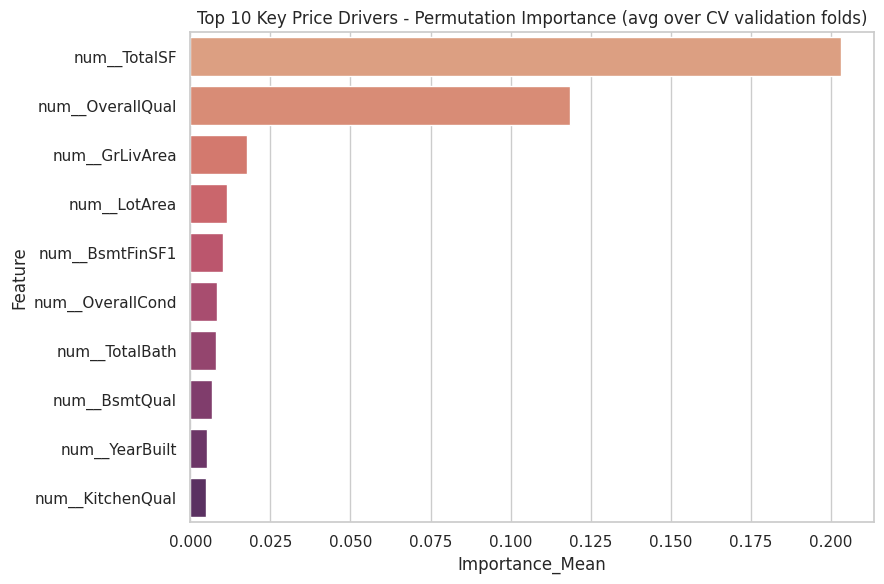

In [26]:
# Permutation importance averaged over 5 CV validation folds (group's official "key price drivers" method)
importance_accum = np.zeros(X_train_final.shape[1])
n_folds = 0
for tr_idx, val_idx in kf.split(X_train_final):
    fold_model = xgb.XGBRegressor(**search.best_params_, random_state=RANDOM_SEED, n_jobs=-1)
    fold_model.fit(X_train_final.iloc[tr_idx], y_train_final[tr_idx])
    result = permutation_importance(fold_model, X_train_final.iloc[val_idx], y_train_final[val_idx],
                                     n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1)
    importance_accum += result.importances_mean
    n_folds += 1

perm_importance_df = pd.DataFrame({
    "Feature": X_train_final.columns, "Importance_Mean": importance_accum / n_folds,
}).sort_values("Importance_Mean", ascending=False)

print("Top 10 key price drivers (permutation importance, averaged over 5 validation folds):")
display(perm_importance_df.head(10))
perm_importance_df.to_csv(RESULTS_DIR / "permutation_importance_cv.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=perm_importance_df.head(10), x="Importance_Mean", y="Feature", palette="flare", ax=ax)
ax.set_title("Top 10 Key Price Drivers - Permutation Importance (avg over CV validation folds)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "permutation_importance.png", dpi=150); plt.show()

## 9. Recommendation, Limitations & Responsible AI

### Recommendation
Use the selected model (**Tuned XGBoost**) as **decision support for initial listing prices**, not an automatic valuation. A valuer enters property characteristics, receives a predicted price plus the top permutation-importance drivers as an explainable sanity-check, and retains final sign-off.

### Limitations
- **Error is not uniform across the price range:** Accuracy is measurably worse at the low and high ends of the market, which is where a bad listing price is most costly. Route predictions in the weakest price band to mandatory manual review.
- **Ames-specific and time-bound:** Trained on one market over a fixed historical window; importances and coefficients will not transfer elsewhere or to a different period without retraining.
- **Stability vs. mean performance:** Factor `CV_RMSE_Std` into the final pick, not just `Test_RMSE`.
- **Static snapshot:** Retrain periodically as market conditions (interest rates, local supply) shift.

### Responsible AI Note (Neighbourhood / Location Features)
`Neighborhood` and other location-correlated fields are high-scrutiny variables: Ames neighbourhood boundaries can carry historical socio-economic patterns. Mitigations:
1. Report `Neighborhood`'s permutation-importance rank explicitly, flagging if it ranks unusually high relative to physical property characteristics.
2. Keep a human valuer in the loop specifically for properties where location is doing most of the predictive work.

> **Note:** The model is decision-support only and should never be shown to a homeowner or buyer as a final, automated valuation.